# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation (04) and modules (05) notebooks are **not produced** — this
unconditional expression notebook follows signatures directly, per the task's renumbering
rule.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the
ends of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that
pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the
mesenchymal / neural-crest FOXC and PRRX factors** (the Kürten 2021 lesson: widen beyond
Snail/Zeb/Twist or the root-end factor is missed) — along *this* trajectory (somitogenesis-high
ductal root → neural-crest terminus) and let the data choose the most end-specific factor at
each end, gated on a 3% expression floor. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 10304 | pseudotime range 0.0 -> 11.78


### Derive the end-specific EMT-TFs (data-driven, robust to a one-sided panel)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root)
vs late (terminus) pseudotime tercile, Spearman correlation with pseudotime, and the
**expression-weighted mean pseudotime of its expressers** (where along the axis the factor
actually concentrates). The two ends are then the earliest- and latest-concentrating factors
among those **robustly expressed (>5%)** — a floor that rejects sparse-gene artifacts (a
factor expressed in <5% of cells has a noise-dominated position; the naive "most-negative
rho" rule would here pick the sparse PRRX2 as a false root factor whose expressers actually
sit *later* than the terminus factor — an incoherent overlay).

**Finding for Lin 2020.** *Every* EMT-TF trends toward the terminus (all rho > 0): the EMT
programme is **neural-crest-loaded**, concentrated at the mesenchymal Crest end, with **no
EMT-TF marking the somitogenesis-high ductal root** (the differentiated epithelial origin).
Among robustly-expressed factors the axis is spanned by **FOXC1** (broad, 13%, root-relative)
→ **SNAI2** (terminus-specific, 10%) — the *same pair* Kürten 2021 derived on HNSCC, arrived
at independently here.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    wmean_t = float(np.average(tn[expr], weights=x[expr])) if expr.sum() else np.nan
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3),
                 round(rho,3), round(wmean_t,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t','wmean_pseudotime'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.05   # robust expression floor: reject sparse-gene position artifacts
ok = df[df.frac_expr > FLOOR].sort_values('wmean_pseudotime')
print(f'\nrobustly expressed (>{FLOOR:.0%}):', list(ok.TF),
      '| all rho > 0 ->', bool((ok.rho_vs_t > 0).all()), '(EMT programme terminus-loaded)')
early_tf = ok.iloc[0]['TF']    # earliest-concentrating (root-relative)
late_tf  = ok.iloc[-1]['TF']   # latest-concentrating (terminus)
print(f'derived pair (earliest -> latest concentrating): {early_tf} -> {late_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t  wmean_pseudotime            end
TWIST1      0.001       0.000      0.001     0.021             0.639 LATE(terminus)
TWIST2      0.002       0.001      0.002     0.034             0.747 LATE(terminus)
 FOXC2      0.004       0.001      0.004     0.036             0.695 LATE(terminus)
  ZEB2      0.024       0.011      0.024     0.067             0.593 LATE(terminus)
 PRRX2      0.032       0.011      0.029     0.069             0.594 LATE(terminus)
  ZEB1      0.050       0.022      0.042     0.076             0.555 LATE(terminus)
 PRRX1      0.013       0.003      0.015     0.087             0.686 LATE(terminus)
 SNAI1      0.038       0.015      0.040     0.093             0.614 LATE(terminus)
 FOXC1      0.129       0.065      0.114     0.099             0.561 LATE(terminus)
 SNAI2      0.101       0.051      0.103     0.132             0.596 LATE(terminus)

robustly expressed (>5%): ['FOXC1', 'SNAI2'] | all rho > 0 -> True (EMT pro

### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30` — the reference categorical
overlay of thresholded expressers on a grey manifold (not a continuous single-gene colormap).
Draw order is set by abundance (broader factor first, sparser on top) so neither marker is
occluded. Each factor is thresholded at the **median expression among its expressing cells**:
for these sparse PDAC EMT-TFs the reference's upper-quartile cut selects a handful of noisy
peak-expression cells whose positions are not representative (they would place SNAI2's peak
*earlier* than FOXC1's, contradicting the derived roles), whereas the median cut shows the
bulk of strong expressers and their geography is coherent — FOXC1 (root-relative) concentrates
earlier than SNAI2 (terminus). Consistent with the terminus-loaded finding the two straddle the
axis midpoint (FOXC1 shown-cell mean pt ~0.45, SNAI2 ~0.55); the modest separation is reported
honestly rather than exaggerated by a sparse-cell threshold.

overlay thresholds (median among expressers): {'FOXC1': 0.623, 'SNAI2': 0.641} | cells shown: {'FOXC1': 661, 'SNAI2': 518}
FOXC1: 12.9% expressing; 661 shown (>median), mean pseudotime of shown cells = 0.45 (all cells = 0.46)
SNAI2: 10.1% expressing; 518 shown (>median), mean pseudotime of shown cells = 0.55 (all cells = 0.46)
shown-cell pseudotime separation (SNAI2 - FOXC1) = +0.10 (positive = terminus factor later)
saved expression.pdf


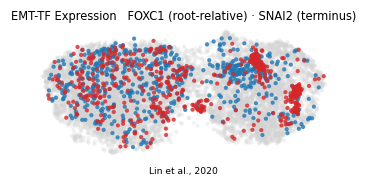

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.50)) if pos.size else 0.0   # median among expressers
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (median among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (root-relative) · {late_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Lin et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (>median), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()
print(f'shown-cell pseudotime separation ({late_tf} - {early_tf}) = {sep:+.2f} (positive = terminus factor later)')
print('saved expression.pdf')